In [1]:
import os
import re
import csv
import numpy as np
import matplotlib.pyplot as plt
import torch

from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from scipy.stats import spearmanr
from scipy.spatial.distance import jensenshannon
from collections import Counter
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModel

# Task 4-6

Task 4 done
Number of lines analysed: 37


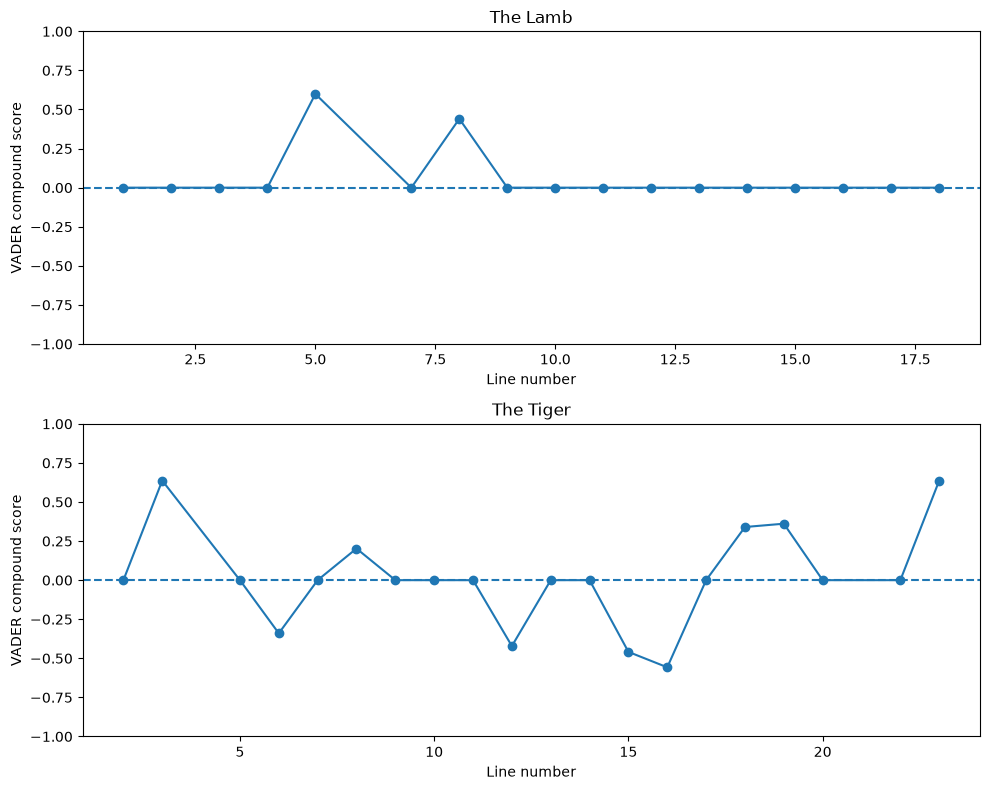


Task 5 done
The Lamb rho = -0.2275 p = 0.3798
The Tiger rho = 0.1054 p = 0.6583


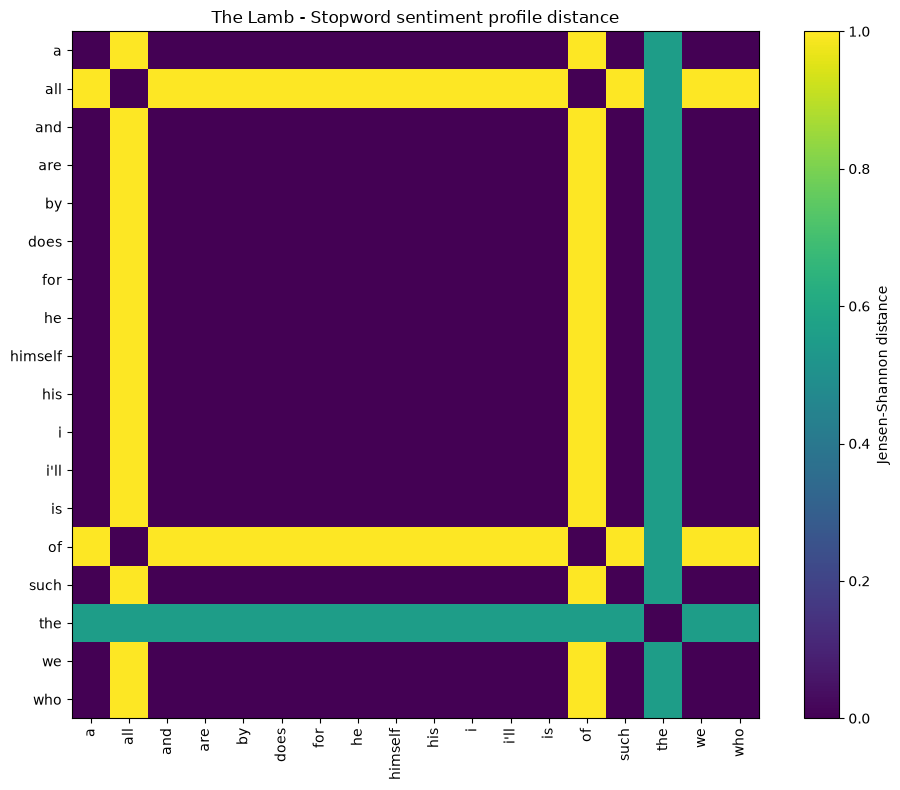

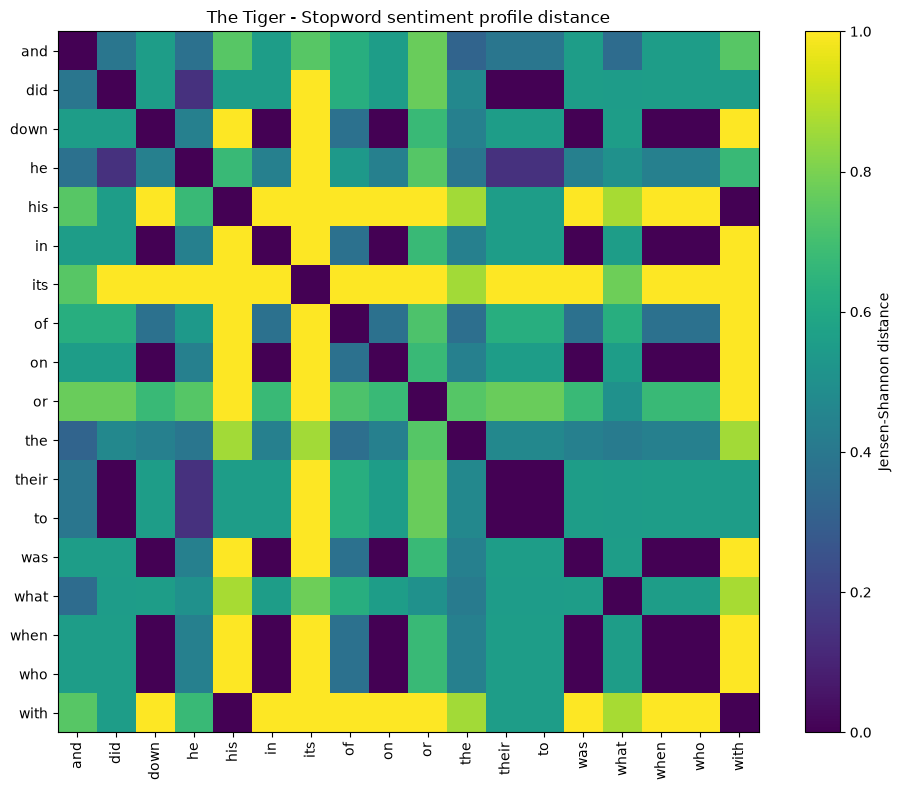


Task 6 done
The Lamb number of stopwords analysed: 18
The Tiger number of stopwords analysed: 18
Histogram counts saved to: ./output/task6/stopword_sentiment_profile_counts.csv
Probability profiles saved to: ./output/task6/stopword_sentiment_profile_probabilities.csv


In [2]:
base_dir = "."

poems = [
    ("The Lamb", os.path.join(base_dir, "poems", "thelamb.txt")),
    ("The Tiger", os.path.join(base_dir, "poems", "thetiger.txt"))
]

stops = set(stopwords.words("english"))
sia = SentimentIntensityAnalyzer()


def tokenize_line(line):
    line = line.replace("’", "'").replace("‘", "'")
    return re.findall(r"[^\W\d_]+(?:'[^\W\d_]+)?", line)


def read_poem_lines(filename):
    lines = []

    with open(filename, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if line != "":
                lines.append(line)

    return lines


def contains_stopword(line):
    tokens = tokenize_line(line)

    for token in tokens:
        if token.lower() in stops:
            return True

    return False


# Task 4

results = []

for title, filename in poems:
    lines = read_poem_lines(filename)

    for line_number, line in enumerate(lines, start=1):

        if contains_stopword(line):
            sentiment = sia.polarity_scores(line)

            results.append([
                title,
                line_number,
                line,
                sentiment["neg"],
                sentiment["neu"],
                sentiment["pos"],
                sentiment["compound"]
            ])


task4_output = os.path.join(base_dir, "output", "task4")
os.makedirs(task4_output, exist_ok=True)

output_file = os.path.join(task4_output, "vader_sentiment.csv")

with open(output_file, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)

    writer.writerow([
        "poem",
        "line_number",
        "line",
        "negative",
        "neutral",
        "positive",
        "compound"
    ])

    writer.writerows(results)


print("Task 4 done")
print("Number of lines analysed:", len(results))


# Task 5

task5_output = os.path.join(base_dir, "output", "task5")
os.makedirs(task5_output, exist_ok=True)

task5_results = []

fig, ax = plt.subplots(2, 1, figsize=(10, 8))

for i in range(len(poems)):
    title = poems[i][0]

    poem_results = [
        row for row in results
        if row[0] == title
    ]

    line_numbers = [row[1] for row in poem_results]
    compound_values = [row[6] for row in poem_results]

    rho, p_value = spearmanr(line_numbers, compound_values)

    task5_results.append([
        title,
        rho,
        p_value
    ])

    ax[i].plot(
        line_numbers,
        compound_values,
        marker="o"
    )

    ax[i].axhline(0, linestyle="--")

    ax[i].set_title(title)
    ax[i].set_xlabel("Line number")
    ax[i].set_ylabel("VADER compound score")
    ax[i].set_ylim(-1, 1)


plt.tight_layout()

plt.show()

plt.close()


spearman_file = os.path.join(
    task5_output,
    "spearman_results.csv"
)

with open(spearman_file, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)

    writer.writerow([
        "poem",
        "spearman_rho",
        "p_value"
    ])

    writer.writerows(task5_results)


print("\nTask 5 done")

for row in task5_results:
    print(
        row[0],
        "rho =", round(row[1], 4),
        "p =", round(row[2], 4)
    )


# Task 6

task6_output = os.path.join(base_dir, "output", "task6")
os.makedirs(task6_output, exist_ok=True)

bin_edges = np.linspace(-1.0, 1.0, 11)

profiles = {}
stopword_line_counts = Counter()

compound_scores = {}

for row in results:
    poem = row[0]
    line_number = row[1]
    compound = row[6]

    compound_scores[(poem, line_number)] = compound


for title, filename in poems:
    lines = read_poem_lines(filename)

    for line_number, line in enumerate(lines, start=1):

        tokens = tokenize_line(line)

        line_stopwords = set()

        for token in tokens:
            word = token.lower()

            if word in stops:
                line_stopwords.add(word)

        if len(line_stopwords) == 0:
            continue

        compound = compound_scores[(title, line_number)]

        bin_number = np.digitize(
            compound,
            bin_edges[1:-1]
        )

        for word in line_stopwords:
            key = (title, word)

            if key not in profiles:
                profiles[key] = np.zeros(10, dtype=int)

            profiles[key][bin_number] += 1
            stopword_line_counts[key] += 1


profile_count_file = os.path.join(
    task6_output,
    "stopword_sentiment_profile_counts.csv"
)

with open(profile_count_file, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)

    header = [
        "poem",
        "stopword",
        "line_count"
    ]

    for i in range(10):
        header.append("bin_" + str(i + 1))

    writer.writerow(header)

    for key in sorted(profiles):
        title, word = key

        writer.writerow([
            title,
            word,
            stopword_line_counts[key],
            *profiles[key]
        ])


probability_profiles = {}

for key in profiles:
    counts = profiles[key].astype(float)
    total = counts.sum()

    if total > 0:
        probability_profiles[key] = counts / total


probability_file = os.path.join(
    task6_output,
    "stopword_sentiment_profile_probabilities.csv"
)

with open(probability_file, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)

    header = [
        "poem",
        "stopword"
    ]

    for i in range(10):
        header.append("bin_" + str(i + 1))

    writer.writerow(header)

    for key in sorted(probability_profiles):
        title, word = key

        writer.writerow([
            title,
            word,
            *probability_profiles[key]
        ])


for title, filename in poems:

    words = [
        word
        for poem_title, word in probability_profiles
        if poem_title == title
    ]

    words = sorted(words)

    distance_matrix = np.zeros(
        (len(words), len(words))
    )

    for i in range(len(words)):
        for j in range(len(words)):

            profile_a = probability_profiles[
                (title, words[i])
            ]

            profile_b = probability_profiles[
                (title, words[j])
            ]

            distance_matrix[i][j] = jensenshannon(
                profile_a,
                profile_b,
                base=2
            )


    safe_title = title.lower().replace(" ", "_")

    distance_file = os.path.join(
        task6_output,
        safe_title + "_sentiment_distances.csv"
    )

    with open(distance_file, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)

        writer.writerow(
            ["stopword"] + words
        )

        for i in range(len(words)):
            writer.writerow(
                [words[i]] + list(distance_matrix[i])
            )


    plt.figure(figsize=(10, 8))

    plt.imshow(
        distance_matrix,
        vmin=0,
        vmax=1
    )

    plt.colorbar(
        label="Jensen-Shannon distance"
    )

    plt.xticks(
        range(len(words)),
        words,
        rotation=90
    )

    plt.yticks(
        range(len(words)),
        words
    )

    plt.title(
        title + " - Stopword sentiment profile distance"
    )

    plt.tight_layout()

    plt.show()

    plt.close()


print("\nTask 6 done")

for title, filename in poems:

    poem_words = [
        word
        for poem_title, word in profiles
        if poem_title == title
    ]

    print(
        title,
        "number of stopwords analysed:",
        len(poem_words)
    )

print(
    "Histogram counts saved to:",
    profile_count_file
)

print(
    "Probability profiles saved to:",
    probability_file
)

# Task 7

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded

Processing: The Lamb

Processing: The Tiger


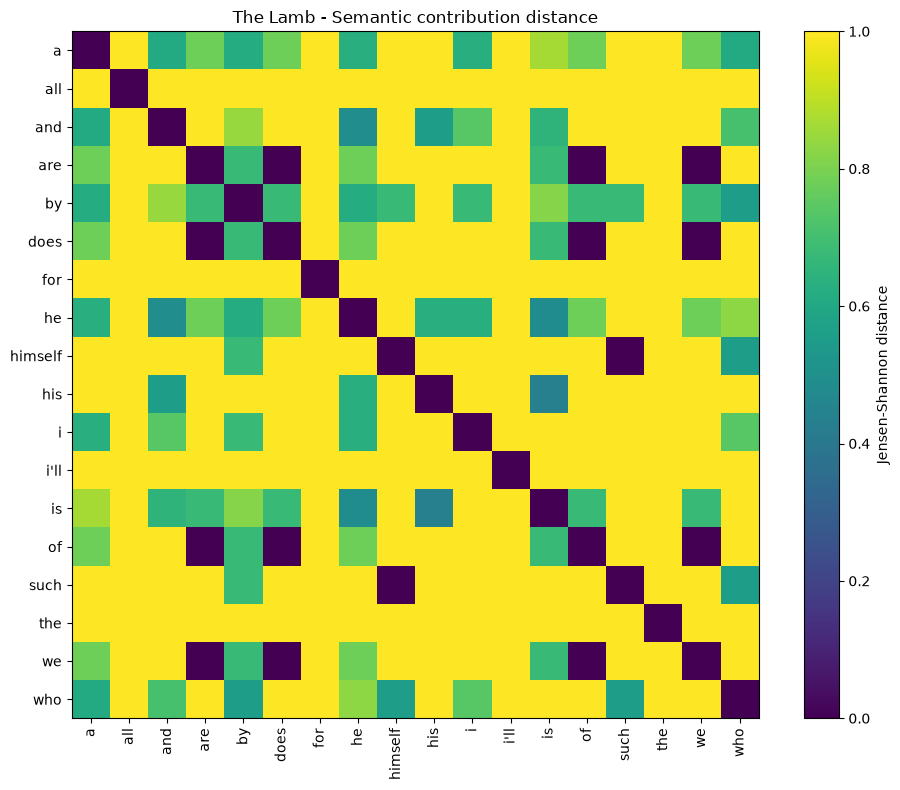

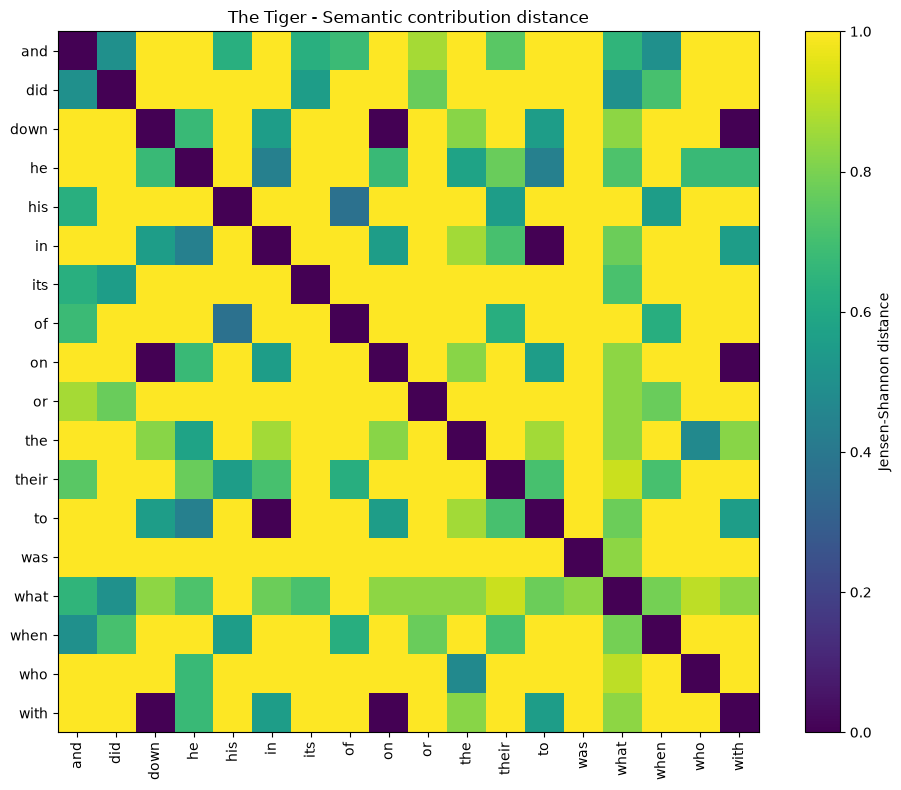


Most contributing stopwords

The Lamb
i'll - mean contribution: 0.2381 - occurrences: 2
does - mean contribution: 0.161 - occurrences: 2
by - mean contribution: 0.1571 - occurrences: 3
is - mean contribution: 0.1506 - occurrences: 3
who - mean contribution: 0.1492 - occurrences: 4

The Tiger
or - mean contribution: 0.1865 - occurrences: 3
did - mean contribution: 0.1691 - occurrences: 2
what - mean contribution: 0.1676 - occurrences: 14
and - mean contribution: 0.1593 - occurrences: 5
their - mean contribution: 0.1498 - occurrences: 2
Contribution value: ./output/task7/stopword_semantic_contributions.csv
Summary  ./output/task7/stopword_contribution_summary.csv
Profiles ./output/task7/stopword_contribution_profiles.csv


In [3]:


base_dir = "."

poems = [
    (
        "The Lamb",
        os.path.join(base_dir, "poems", "thelamb.txt")
    ),
    (
        "The Tiger",
        os.path.join(base_dir, "poems", "thetiger.txt")
    )
]

output_dir = os.path.join(
    base_dir,
    "output",
    "task7"
)

os.makedirs(output_dir, exist_ok=True)


# stopwords

stops = set(stopwords.words("english"))


# tokenizer used for poem words

def tokenize_line(line):
    line = line.replace("’", "'").replace("‘", "'")

    return re.findall(
        r"[^\W\d_]+(?:'[^\W\d_]+)?",
        line
    )


# read poem and remove empty lines

def read_poem_lines(filename):
    lines = []

    with open(filename, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if line != "":
                lines.append(line)

    return lines


# load BERT

tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)

model = AutoModel.from_pretrained(
    "bert-base-uncased"
)
model.eval()


print("BERT loaded")
def get_bert_embedding(text):
    encoded = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    with torch.no_grad():
        output = model(**encoded)

    hidden = output.last_hidden_state[0]

   
    if hidden.shape[0] > 2:
        hidden = hidden[1:-1]

    embedding = hidden.mean(dim=0)

    return embedding.numpy()

# semantic contribution

contribution_rows = []


for title, filename in poems:

    print("\nProcessing:", title)

    lines = read_poem_lines(filename)

    for line_number, line in enumerate(
        lines,
        start=1
    ):

        words = tokenize_line(line)

        if len(words) == 0:
            continue

        # check if the line contains at least one stopword
        line_stopwords = []

        for word in words:
            if word.lower() in stops:
                line_stopwords.append(
                    word.lower()
                )

        if len(line_stopwords) == 0:
            continue

        # embedding for whole line
        line_embedding = get_bert_embedding(line)

        similarities = []

       
        for word in words:

            word_embedding = get_bert_embedding(
                word
            )

            similarity = cosine_similarity(
                [line_embedding],
                [word_embedding]
            )[0][0]

            similarities.append([
                word,
                similarity
            ])

        similarity_sum = sum(
            item[1]
            for item in similarities
        )

        if abs(similarity_sum) < 1e-12:
            continue

        for word, similarity in similarities:

            word_lower = word.lower()

            if word_lower in stops:

                contribution = (
                    similarity /
                    similarity_sum
                )

                contribution_rows.append([
                    title,
                    line_number,
                    line,
                    word_lower,
                    similarity,
                    contribution
                ])



# save contribution values


contribution_file = os.path.join(
    output_dir,
    "stopword_semantic_contributions.csv"
)

with open(
    contribution_file,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.writer(file)

    writer.writerow([
        "poem",
        "line_number",
        "line",
        "stopword",
        "cosine_similarity",
        "contribution"
    ])

    writer.writerows(
        contribution_rows
    )



# stopword summary


summary_rows = []


for title, filename in poems:

    poem_words = {}

    for row in contribution_rows:

        if row[0] != title:
            continue

        word = row[3]
        contribution = row[5]

        if word not in poem_words:
            poem_words[word] = []

        poem_words[word].append(
            contribution
        )

    for word in sorted(poem_words):

        values = poem_words[word]

        summary_rows.append([
            title,
            word,
            len(values),
            np.mean(values),
            np.median(values),
            np.std(values),
            np.min(values),
            np.max(values)
        ])


summary_file = os.path.join(
    output_dir,
    "stopword_contribution_summary.csv"
)

with open(
    summary_file,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.writer(file)

    writer.writerow([
        "poem",
        "stopword",
        "count",
        "mean_contribution",
        "median_contribution",
        "standard_deviation",
        "minimum",
        "maximum"
    ])

    writer.writerows(
        summary_rows
    )



# make 10-bin contribution profiles


contribution_profiles = {}


for title, filename in poems:

    poem_rows = []

    for row in contribution_rows:
        if row[0] == title:
            poem_rows.append(row)

    if len(poem_rows) == 0:
        continue

    values = [
        row[5]
        for row in poem_rows
    ]

    minimum = min(values)
    maximum = max(values)

    if minimum == maximum:
        maximum = minimum + 0.000001

    # use the same bin range for all stopwords
    # inside one poem
    bin_edges = np.linspace(
        minimum,
        maximum,
        11
    )

    for row in poem_rows:

        word = row[3]
        contribution = row[5]

        key = (
            title,
            word
        )

        if key not in contribution_profiles:

            contribution_profiles[key] = np.zeros(
                10,
                dtype=int
            )

        bin_number = np.digitize(
            contribution,
            bin_edges[1:-1]
        )

        contribution_profiles[
            key
        ][bin_number] += 1



# save contribution histograms


profile_file = os.path.join(
    output_dir,
    "stopword_contribution_profiles.csv"
)

with open(
    profile_file,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.writer(file)

    header = [
        "poem",
        "stopword",
        "count"
    ]

    for i in range(10):
        header.append(
            "bin_" + str(i + 1)
        )

    writer.writerow(
        header
    )

    for key in sorted(
        contribution_profiles
    ):

        title, word = key

        counts = contribution_profiles[
            key
        ]

        writer.writerow([
            title,
            word,
            int(counts.sum()),
            *counts
        ])



# comparing contribution distributions


for title, filename in poems:

    words = []

    for poem_title, word in contribution_profiles:

        if poem_title == title:
            words.append(word)

    words = sorted(words)

    if len(words) == 0:
        continue

    distance_matrix = np.zeros(
        (
            len(words),
            len(words)
        )
    )

    for i in range(len(words)):

        for j in range(len(words)):

            profile_a = contribution_profiles[
                (title, words[i])
            ].astype(float)

            profile_b = contribution_profiles[
                (title, words[j])
            ].astype(float)

            profile_a = (
                profile_a /
                profile_a.sum()
            )

            profile_b = (
                profile_b /
                profile_b.sum()
            )

            distance = jensenshannon(
                profile_a,
                profile_b,
                base=2
            )

            distance_matrix[
                i,
                j
            ] = distance


    safe_title = (
        title
        .lower()
        .replace(" ", "_")
    )


   

    distance_file = os.path.join(
        output_dir,
        safe_title
        + "_contribution_distances.csv"
    )

    with open(
        distance_file,
        "w",
        newline="",
        encoding="utf-8"
    ) as file:

        writer = csv.writer(file)

        writer.writerow(
            ["stopword"] + words
        )

        for i in range(len(words)):

            writer.writerow(
                [words[i]]
                + list(
                    distance_matrix[i]
                )
            )


    # heatmap

    plt.figure(
        figsize=(10, 8)
    )

    plt.imshow(
        distance_matrix,
        vmin=0,
        vmax=1
    )

    plt.colorbar(
        label="Jensen-Shannon distance"
    )

    plt.xticks(
        range(len(words)),
        words,
        rotation=90
    )

    plt.yticks(
        range(len(words)),
        words
    )

    plt.title(
        title
        + " - Semantic contribution distance"
    )

    plt.tight_layout()

    heatmap_file = os.path.join(
        output_dir,
        safe_title
        + "_contribution_heatmap.png"
    )

    plt.show()

    plt.close()



# print stopwords with highest average contribution
print("\nMost contributing stopwords")


for title, filename in poems:

    poem_summary = []

    for row in summary_rows:

        if row[0] == title:
            poem_summary.append(row)

    # only use stopwords appearing at least twice
    repeated_words = [
        row
        for row in poem_summary
        if row[2] >= 2
    ]

    repeated_words = sorted(
        repeated_words,
        key=lambda row: row[3],
        reverse=True
    )

    print("\n" + title)

    for row in repeated_words[:5]:

        print(
            row[1],
            "- mean contribution:",
            round(row[3], 4),
            "- occurrences:",
            row[2]
        )


print("Contribution value:",contribution_file)

print("Summary ",summary_file)

print("Profiles",profile_file)
